# 🌳 Decision Tree Classification — Bank Marketing

**Course:** Big Data and Machine Learning · **Module 02:** Build and Evaluate Decision Tree Models

In this notebook we build, train, evaluate and visualize a **Decision Tree Classifier** that predicts whether a bank
customer will subscribe to a term **deposit** after a marketing campaign.

### 🎯 Learning objectives
By the end of this notebook you should be able to:
1. Explain how a decision tree makes predictions and how it **chooses splits**.
2. Compute **Gini impurity**, **entropy** and **information gain** by hand (and in code).
3. Build a full scikit-learn `Pipeline` (pre-processing ➜ model).
4. Evaluate a classifier with the **confusion matrix, accuracy, precision, recall and F1**.
5. Visualize and interpret a trained tree and its **feature importances**.
6. Diagnose **overfitting** and tune hyper-parameters with **cross-validation**.

### 📑 Contents
1. Concepts: what is a decision tree?
2. The mathematics of splitting (Gini, Entropy, Information Gain)
3. Load & explore the data
4. Clean & transform the data
5. Build the pipeline and train the model
6. Evaluate the model (metrics + math)
7. Visualize the tree
8. Feature importance
9. Overfitting & the bias–variance trade-off
10. Hyper-parameter tuning with cross-validation
11. Summary & exercises

## 1. Concepts: what is a decision tree?

A decision tree is a **flowchart-like model** that predicts a target by asking a sequence of *yes/no* questions about the features.

```
                 [duration <= 365.5 ?]          <- root node (first question)
                 /                    \
              yes                      no
              /                          \
     [housing = yes ?]            [duration <= 600 ?]   <- internal (decision) nodes
       /        \                   /          \
   "No"        "No"             "Deposit"   "Deposit"   <- leaf nodes (predictions)
```

| Term | Meaning |
|------|---------|
| **Root node** | The first split, applied to *all* training samples |
| **Internal / decision node** | A node that tests a feature: $x_j \le t$ |
| **Leaf (terminal) node** | Holds the prediction (majority class for classification) |
| **Depth** | Number of questions from the root to a leaf |
| **Impurity** | How *mixed* the classes are inside a node |

**How the tree is grown (CART algorithm, used by scikit-learn):**
1. Start with all training samples in the root.
2. For every feature $j$ and every candidate threshold $t$, split the node into
   $L = \{x : x_j \le t\}$ and $R = \{x : x_j > t\}$.
3. Choose the split that **reduces impurity the most**.
4. Repeat recursively on each child until a stopping rule is hit (`max_depth`, `min_samples_split`, pure node …).

This is a **greedy**, top-down, recursive partitioning of the feature space into axis-aligned rectangles.

## 2. The mathematics of splitting

Let a node contain $N$ samples, and let $p_k$ be the proportion of samples in that node belonging to class $k$ (out of $K$ classes).

### 2.1 Gini impurity
$$
G = 1 - \sum_{k=1}^{K} p_k^2
$$
* $G = 0$ ➜ the node is **pure** (all samples belong to one class).
* For two classes the maximum is $G = 0.5$ (a 50/50 mix).
* Interpretation: probability of mis-labelling a random sample if we label it randomly according to the node's class distribution.

### 2.2 Entropy
$$
H = -\sum_{k=1}^{K} p_k \log_2 p_k
$$
* $H = 0$ ➜ pure node; for two classes the maximum is $H = 1$ bit.
* Comes from information theory: the average number of bits needed to encode the class of a sample.

### 2.3 Impurity decrease / Information gain
For a split of the parent node $P$ into children $L$ and $R$:
$$
\Delta I = I(P) - \left( \frac{N_L}{N_P} I(L) + \frac{N_R}{N_P} I(R) \right)
$$
where $I$ is Gini or Entropy. When $I$ = entropy, $\Delta I$ is called **information gain**.
The tree picks the feature $j$ and threshold $t$ that **maximize** $\Delta I$:
$$
(j^*, t^*) = \arg\max_{j,\,t} \; \Delta I(j, t)
$$

### 2.4 A tiny worked example
A node has **10** customers: 6 *No* and 4 *Deposit*.
$$
G_P = 1 - (0.6^2 + 0.4^2) = 1 - (0.36 + 0.16) = 0.48
$$
Suppose a split sends 5 customers left (5 No, 0 Deposit) and 5 right (1 No, 4 Deposit):
$$
G_L = 1 - (1^2 + 0^2) = 0, \qquad G_R = 1 - (0.2^2 + 0.8^2) = 0.32
$$
$$
\Delta G = 0.48 - \left(\tfrac{5}{10}\cdot 0 + \tfrac{5}{10}\cdot 0.32\right) = 0.48 - 0.16 = 0.32
$$
Let's verify this — and visualize both impurity measures — in code.

In [1]:
# Importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
# Impurity functions written from the formulas above
def gini(counts):
    p = np.asarray(counts, dtype=float) / np.sum(counts)
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.asarray(counts, dtype=float) / np.sum(counts)
    p = p[p > 0]                      # 0 * log(0) is defined as 0
    return -np.sum(p * np.log2(p))

def impurity_decrease(parent, left, right, impurity=gini):
    n_p, n_l, n_r = np.sum(parent), np.sum(left), np.sum(right)
    return impurity(parent) - (n_l / n_p * impurity(left) + n_r / n_p * impurity(right))

parent, left, right = [6, 4], [5, 0], [1, 4]
print(f"Gini(parent) = {gini(parent):.3f}   Gini(left) = {gini(left):.3f}   Gini(right) = {gini(right):.3f}")
print(f"Gini decrease          = {impurity_decrease(parent, left, right, gini):.3f}")
print(f"Entropy(parent)        = {entropy(parent):.3f} bits")
print(f"Information gain       = {impurity_decrease(parent, left, right, entropy):.3f} bits")

Gini(parent) = 0.480   Gini(left) = 0.000   Gini(right) = 0.320
Gini decrease          = 0.320
Entropy(parent)        = 0.971 bits
Information gain       = 0.610 bits


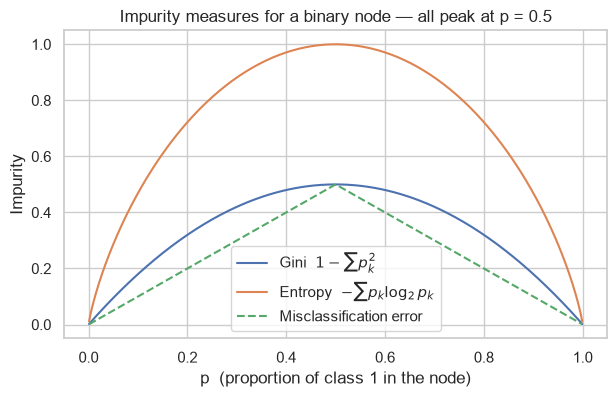

In [3]:
# How do Gini and Entropy behave for a two-class node as p (share of class 1) changes?
p = np.linspace(0.001, 0.999, 300)
gini_curve = 1 - (p**2 + (1 - p)**2)
entropy_curve = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
misclass = 1 - np.maximum(p, 1 - p)

plt.figure(figsize=(7, 4))
plt.plot(p, gini_curve, label="Gini  $1-\\sum p_k^2$")
plt.plot(p, entropy_curve, label="Entropy  $-\\sum p_k\\log_2 p_k$")
plt.plot(p, misclass, "--", label="Misclassification error")
plt.xlabel("p  (proportion of class 1 in the node)")
plt.ylabel("Impurity")
plt.title("Impurity measures for a binary node — all peak at p = 0.5")
plt.legend()
plt.show()

## 3. Load & explore the dataset

The **Bank Marketing** dataset describes customers contacted in a phone campaign. The target column `deposit`
says whether the customer subscribed (`yes`) or not (`no`).

> 💡 The CSV is loaded with a **relative path**, so the notebook runs as-is after you clone/fork the repository.
> On Google Colab the file is downloaded automatically from the GitHub repository.

In [4]:
# -------------------------------
# Load the Data
# -------------------------------
import os
# Use the local file if present (cloned/forked repo), otherwise download it from GitHub (e.g. on Colab)
DATA_PATH = "content/bank_marketing.csv" if os.path.exists("content/bank_marketing.csv") else "https://raw.githubusercontent.com/ab3lT/decision-trees-big-data-ml/main/content/bank_marketing.csv"
data = pd.read_csv(DATA_PATH)

print(f"Shape: {data.shape[0]} rows x {data.shape[1]} columns\n")
# Print dataset schema (column names and data types)
print("Dataset Schema:")
print(data.dtypes)

Shape: 11162 rows x 17 columns

Dataset Schema:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
deposit        str
dtype: object


In [5]:
# Show the first 5 rows of the dataset
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [6]:
# -------------------------------
# Data Exploration
# -------------------------------

# Identify categorical columns (String or Boolean types)
categorical_cols = data.select_dtypes(include=['object', 'string', 'bool']).columns.tolist()

# Loop through each categorical column and get the count of distinct values
for col_name in categorical_cols:
    distinct_count = data[col_name].nunique()
    print(f"Column: {col_name:<10} - Distinct Count: {distinct_count}")

Column: job        - Distinct Count: 12
Column: marital    - Distinct Count: 3
Column: education  - Distinct Count: 4
Column: default    - Distinct Count: 2
Column: housing    - Distinct Count: 2
Column: loan       - Distinct Count: 2
Column: contact    - Distinct Count: 3
Column: month      - Distinct Count: 12
Column: poutcome   - Distinct Count: 4
Column: deposit    - Distinct Count: 2


In [7]:
# Data Summary
data.describe(include='all')

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
count,11162.000000,11162,11162,11162,11162,11162.000000,11162,11162,11162,11162.000000,11162,11162.000000,11162.000000,11162.000000,11162.000000,11162,11162
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,management,married,secondary,no,NaN,no,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,2566,6351,5476,10994,NaN,5881,9702,8042,NaN,2824,NaN,NaN,NaN,NaN,8326,5873
mean,41.231948,NaN,NaN,NaN,NaN,1528.538524,NaN,NaN,NaN,15.658036,NaN,371.993818,2.508421,51.330407,0.832557,NaN,NaN
std,11.913369,NaN,NaN,NaN,NaN,3225.413326,NaN,NaN,NaN,8.420740,NaN,347.128386,2.722077,108.758282,2.292007,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-6847.000000,NaN,NaN,NaN,1.000000,NaN,2.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,32.000000,NaN,NaN,NaN,NaN,122.000000,NaN,NaN,NaN,8.000000,NaN,138.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,550.000000,NaN,NaN,NaN,15.000000,NaN,255.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,49.000000,NaN,NaN,NaN,NaN,1708.000000,NaN,NaN,NaN,22.000000,NaN,496.000000,3.000000,20.750000,1.000000,NaN,NaN


### Is the target balanced?
If one class dominated (e.g. 95 % *No*), **accuracy** would be misleading — a model that always predicts *No*
would score 95 %. Here the classes are roughly balanced, so accuracy is a reasonable first metric, but we will
still look at precision, recall and F1.

Target Variable Distribution:
deposit
no     5873
yes    5289
Name: count, dtype: int64

Proportions:
deposit
no     0.526
yes    0.474
Name: proportion, dtype: float64


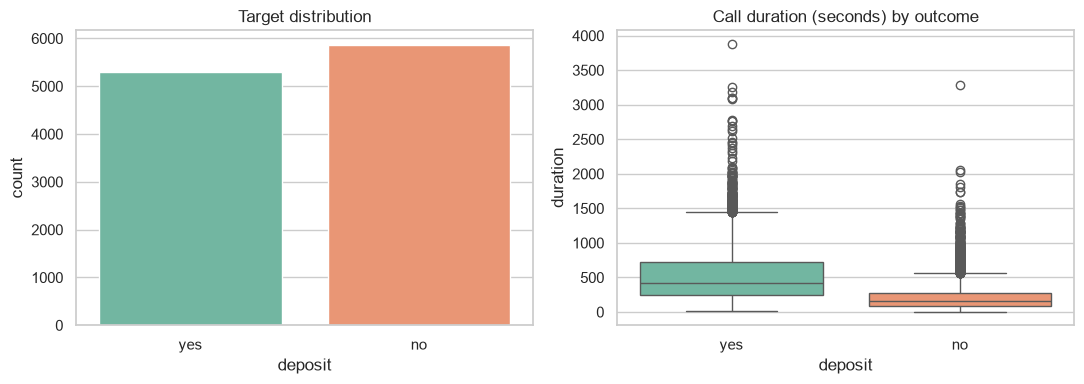

In [8]:
# To check if the data is balanced for the values in target variable
print("Target Variable Distribution:")
print(data['deposit'].value_counts())
print("\nProportions:")
print(data['deposit'].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='deposit', data=data, ax=axes[0], palette="Set2", hue='deposit', legend=False)
axes[0].set_title("Target distribution")
sns.boxplot(x='deposit', y='duration', data=data, ax=axes[1], palette="Set2", hue='deposit', legend=False)
axes[1].set_title("Call duration (seconds) by outcome")
plt.tight_layout()
plt.show()

## 4. Clean & transform the data

The dataset encodes missing values as the string `'unknown'`. Let's count them per categorical column.

In [9]:
# Function to check for 'unknown' values in categorical columns
def check_unknown_in_columns(data, categorical_columns):
    '''
    Identifies the number of occurrences of 'unknown' in each categorical column.

    :param data: Pandas DataFrame
    :param categorical_columns: List of categorical column names
    '''
    for col in categorical_columns:
        na_count = (data[col] == 'unknown').sum()
        if na_count > 0:
            print(f"Column: {col:<10} - 'unknown' Occurrences: {na_count} ({na_count / len(data):.1%})")

check_unknown_in_columns(data, categorical_cols)

Column: job        - 'unknown' Occurrences: 70 (0.6%)
Column: education  - 'unknown' Occurrences: 497 (4.5%)
Column: contact    - 'unknown' Occurrences: 2346 (21.0%)
Column: poutcome   - 'unknown' Occurrences: 8326 (74.6%)


**Cleaning decisions**
* `contact` and `poutcome` have a very large share of `'unknown'` values ➜ **drop the columns**.
* `marital` is dropped to avoid bias and help ensure fairness in the model (we do not want marital status to drive a financial decision).
* Remaining `'unknown'` values (in `job`, `education`) are few ➜ **drop those rows**.

In [10]:
# Dropping the 'contact' and 'poutcome' columns since they have too many unknown values
# Dropping 'marital' column to avoid the bias and ensure fairness in the model
data = data.drop(columns=['contact', 'poutcome', 'marital'])

# Replace any 'unknown' values with nulls and drop rows with nulls
data = data.replace('unknown', np.nan).dropna()
print(f"Data after cleaning: Rows - {data.shape[0]}, Columns - {data.shape[1]}")

Data after cleaning: Rows - 10634, Columns - 14


### Feature selection & encoding

| Step | Why |
|------|-----|
| **One-hot encoding** of categorical columns | Trees in scikit-learn need numbers. A column `job` with values `{admin, technician, …}` becomes binary columns `job_technician ∈ {0,1}`, … `drop='first'` removes one redundant column per feature. |
| **Standard scaling** of numeric columns $z = \dfrac{x - \mu}{\sigma}$ | ⚠️ *Decision trees do **not** need scaling* — a split $x \le t$ is the same as $z \le (t-\mu)/\sigma$. We keep it so the pipeline is reusable with scale-sensitive models (e.g. logistic regression, KNN). |
| **Label encoding** of the target | `no ➜ 0`, `yes ➜ 1` |

In [11]:
# Update the categorical and numerical columns used as features
categorical_cols = ['job', 'education', 'default', 'housing', 'loan']
numeric_cols = ['age', 'balance', 'duration']

# Encode categorical features & standardize numerical features
categorical_encoder = OneHotEncoder(handle_unknown='ignore', drop='first')
numeric_scaler = StandardScaler()

# Any column not listed here is dropped by the ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', numeric_scaler, numeric_cols),
    ('cat', categorical_encoder, categorical_cols)
])

# Encode target variable: 'no' -> 0, 'yes' -> 1
label_encoder = LabelEncoder()
data['deposit'] = label_encoder.fit_transform(data['deposit'])
print("Target classes:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Target classes: {'no': np.int64(0), 'yes': np.int64(1)}


## 5. Build the pipeline and train the model

We hold out **20 %** of the data as a test set. `stratify=y` keeps the same class proportions in train and test.

The model is `DecisionTreeClassifier(criterion='gini', max_depth=5)`:
* `criterion='gini'` ➜ use the Gini impurity from Section 2 to score splits (`'entropy'` is the alternative).
* `max_depth=5` ➜ **pre-pruning**: stop growing after 5 levels to limit overfitting.

In [12]:
# Split data into features (X) and target (y)
X = data.drop(columns=['deposit'])
y = data['deposit']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Create a pipeline with preprocessor and Decision Tree model
dt = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=RANDOM_STATE)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', dt)
])

# Train the model
pipeline.fit(X_train, y_train)

# Make predictions
y_pred = pipeline.predict(X_test)

# Show some predictions
df = pd.DataFrame({'Actual': y_test, 'Predictions': y_pred})
print(df.head(10).to_string(index=False))

Train: (8507, 13), Test: (2127, 13)
 Actual  Predictions
      0            0
      0            0
      0            1
      0            0
      1            0
      1            1
      0            0
      1            0
      0            0
      1            1


### 🔎 Check the math: reproduce the root split by hand
The root node contains all training samples. Let's compute its Gini impurity from the class counts, and then
search **every threshold** of the numeric features ourselves to see that the best split matches the one scikit-learn found.

In [13]:
counts = np.bincount(y_train)
print(f"Root class counts (No, Deposit): {counts}")
print(f"Gini(root) by hand    : {gini(counts):.4f}")
print(f"Gini(root) by sklearn : {pipeline.named_steps['classifier'].tree_.impurity[0]:.4f}")

def best_threshold(x, y):
    '''Brute-force search of the threshold that maximizes the Gini decrease for one numeric feature.'''
    order = np.argsort(x)
    x, y = x[order], y[order]
    parent = np.bincount(y, minlength=2)
    best = (0, None)
    left = np.zeros(2)
    for i in range(len(x) - 1):
        left[y[i]] += 1
        if x[i] == x[i + 1]:
            continue                      # can only split between distinct values
        right = parent - left
        gain = impurity_decrease(parent, left, right, gini)
        if gain > best[0]:
            best = (gain, (x[i] + x[i + 1]) / 2)   # sklearn uses the midpoint
    return best

print("\nBest split per numeric feature (raw units):")
for col in numeric_cols:
    gain, thr = best_threshold(X_train[col].to_numpy(), y_train.to_numpy())
    print(f"  {col:<9} threshold = {thr:>9.1f}   Gini decrease = {gain:.4f}")

Root class counts (No, Deposit): [4490 4017]
Gini(root) by hand    : 0.4985
Gini(root) by sklearn : 0.4985

Best split per numeric feature (raw units):
  age       threshold =      60.5   Gini decrease = 0.0145


  balance   threshold =     223.5   Gini decrease = 0.0090

  duration  threshold =     365.5   Gini decrease = 0.1004


In [14]:
# Which feature/threshold did sklearn choose at the root?  (thresholds are in *scaled* units)
tree = pipeline.named_steps['classifier'].tree_
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
root_feat, root_thr = feature_names[tree.feature[0]], tree.threshold[0]

# Convert the scaled threshold back to raw units:  x = z * sigma + mu
scaler = pipeline.named_steps['preprocessor'].named_transformers_['num']
idx = numeric_cols.index(root_feat.replace('num__', ''))
raw_thr = root_thr * scaler.scale_[idx] + scaler.mean_[idx]
print(f"sklearn root split: {root_feat} <= {root_thr:.4f} (scaled)  ==  {raw_thr:.1f} (raw)")

sklearn root split: num__duration <= -0.0274 (scaled)  ==  365.5 (raw)


The hand-computed best threshold matches scikit-learn's root split — the tree really is just repeatedly applying
$\arg\max \Delta G$. 🎉

## 6. Evaluate the model

### 6.1 Confusion matrix
|                     | Predicted **No (0)** | Predicted **Deposit (1)** |
|---------------------|:--------------------:|:-------------------------:|
| **Actual No (0)**   | TN (true negative)   | FP (false positive)       |
| **Actual Deposit (1)** | FN (false negative) | TP (true positive)       |

### 6.2 Metrics
$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
\qquad
\text{Precision} = \frac{TP}{TP + FP}
\qquad
\text{Recall} = \frac{TP}{TP + FN}
$$
$$
F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
\quad\text{(harmonic mean of precision and recall)}
$$

* **Precision** — of the customers we *predicted* would subscribe, how many actually did? (cost of wasted calls)
* **Recall** — of the customers who *actually* subscribed, how many did we find? (cost of missed customers)

In [15]:
# Evaluate the model using scikit-learn
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Evaluation Metrics")
print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1 Score : {f1:.3f}")

Evaluation Metrics
Accuracy : 0.764
Precision: 0.738
Recall   : 0.776
F1 Score : 0.757


TN=847  FP=276  FN=225  TP=779

Accuracy  = (779+847) / 2127 = 0.764
Precision = 779 / (779+276) = 0.738
Recall    = 779 / (779+225) = 0.776
F1        = 0.757


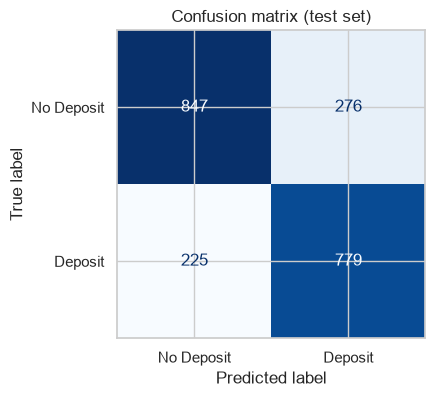

In [16]:
# Re-compute the same metrics directly from the confusion matrix (the formulas above)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}\n")

acc_hand = (tp + tn) / (tp + tn + fp + fn)
prec_hand = tp / (tp + fp)
rec_hand = tp / (tp + fn)
f1_hand = 2 * prec_hand * rec_hand / (prec_hand + rec_hand)
print(f"Accuracy  = ({tp}+{tn}) / {tp+tn+fp+fn} = {acc_hand:.3f}")
print(f"Precision = {tp} / ({tp}+{fp}) = {prec_hand:.3f}")
print(f"Recall    = {tp} / ({tp}+{fn}) = {rec_hand:.3f}")
print(f"F1        = {f1_hand:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Deposit', 'Deposit'],
                                        cmap='Blues', ax=ax, colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.show()

In [17]:
print(classification_report(y_test, y_pred, target_names=['No Deposit', 'Deposit']))

              precision    recall  f1-score   support

  No Deposit       0.79      0.75      0.77      1123
     Deposit       0.74      0.78      0.76      1004

    accuracy                           0.76      2127
   macro avg       0.76      0.77      0.76      2127
weighted avg       0.77      0.76      0.76      2127


## 7. Visualize the decision tree

Each box shows:
* the **split rule** (e.g. `num__duration <= -0.43`, in scaled units),
* the node's **gini** impurity,
* **samples** — how many training rows reach the node,
* **value** — the class counts/proportions `[No, Deposit]`,
* **class** — the majority class = the prediction if this were a leaf.

Colour intensity encodes purity: orange ➜ *No Deposit*, blue ➜ *Deposit*.
We show only the top 3 levels so it stays readable.

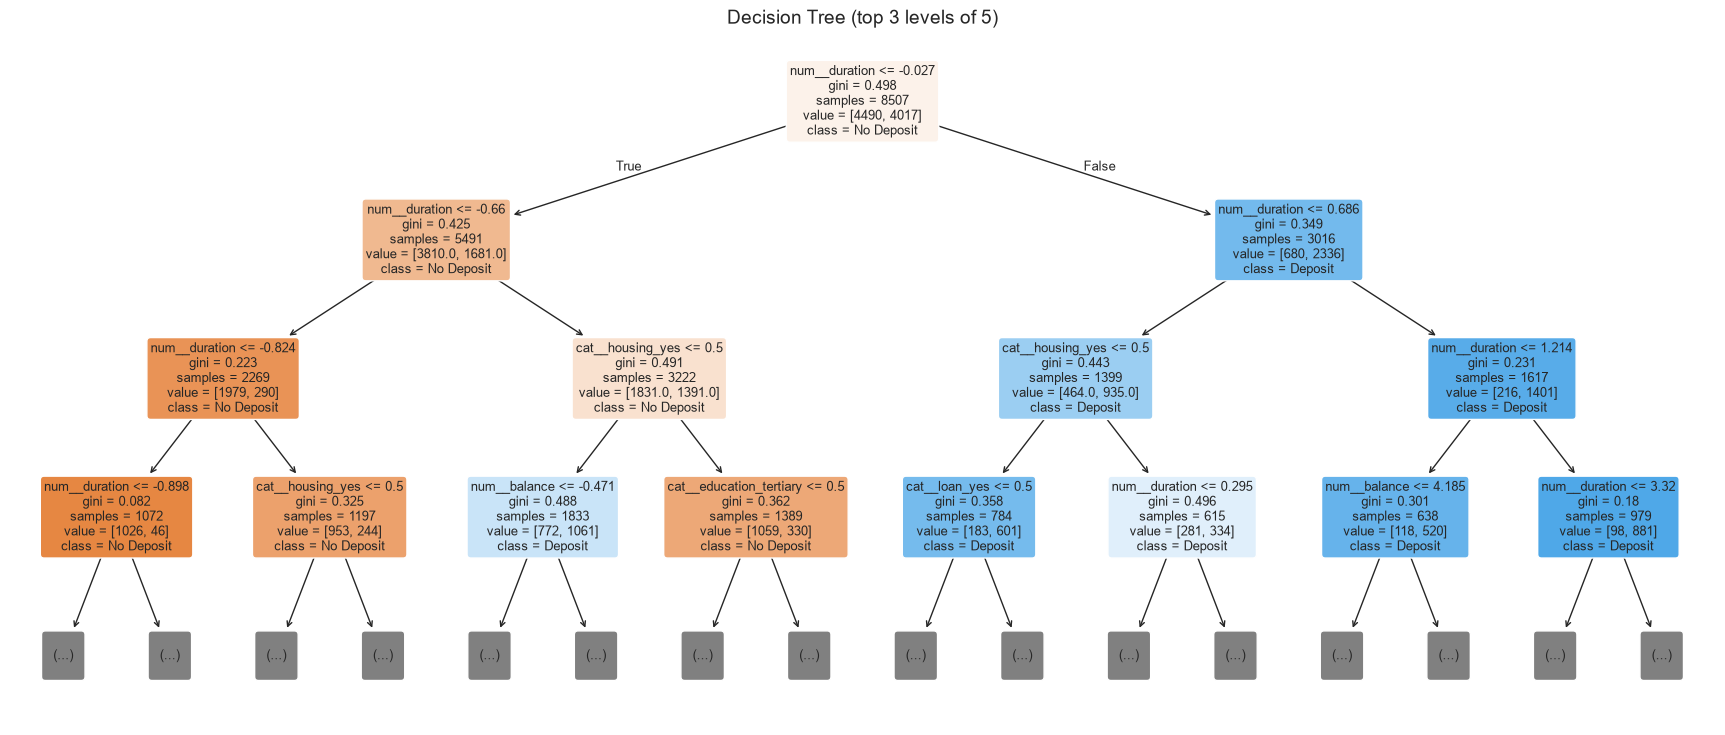

In [18]:
# Get transformed feature names and the trained Decision Tree from the pipeline
transformed_feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
dt_model = pipeline.named_steps['classifier']

plt.figure(figsize=(22, 9))
plot_tree(dt_model,
          feature_names=transformed_feature_names,
          class_names=['No Deposit', 'Deposit'],
          filled=True, rounded=True, max_depth=3, fontsize=9, impurity=True, proportion=False)
plt.title("Decision Tree (top 3 levels of 5)", fontsize=14)
plt.show()

In [19]:
# The full tree as text rules — handy for reading every path from root to leaf
print(export_text(dt_model, feature_names=list(transformed_feature_names), max_depth=5))

|--- num__duration <= -0.03
|   |--- num__duration <= -0.66
|   |   |--- num__duration <= -0.82
|   |   |   |--- num__duration <= -0.90
|   |   |   |   |--- num__age <= 2.61
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- num__age >  2.61
|   |   |   |   |   |--- class: 0
|   |   |   |--- num__duration >  -0.90
|   |   |   |   |--- cat__job_student <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- cat__job_student >  0.50
|   |   |   |   |   |--- class: 1
|   |   |--- num__duration >  -0.82
|   |   |   |--- cat__housing_yes <= 0.50
|   |   |   |   |--- num__age <= -1.15
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- num__age >  -1.15
|   |   |   |   |   |--- class: 0
|   |   |   |--- cat__housing_yes >  0.50
|   |   |   |   |--- num__age <= 1.67
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- num__age >  1.67
|   |   |   |   |   |--- class: 1
|   |--- num__duration >  -0.66
|   |   |--- cat__housing_yes <= 0.50
|   |   |   |--- num__balance <= -0.47
|

## 8. Feature importance

scikit-learn's (Gini) importance of feature $j$ sums the **weighted impurity decrease** of every node $t$ that splits on $j$:
$$
\text{Imp}(j) = \sum_{t \,:\, \text{split on } j} \frac{N_t}{N}\left( I(t) - \frac{N_{t_L}}{N_t} I(t_L) - \frac{N_{t_R}}{N_t} I(t_R) \right)
$$
and the values are normalized to sum to 1.

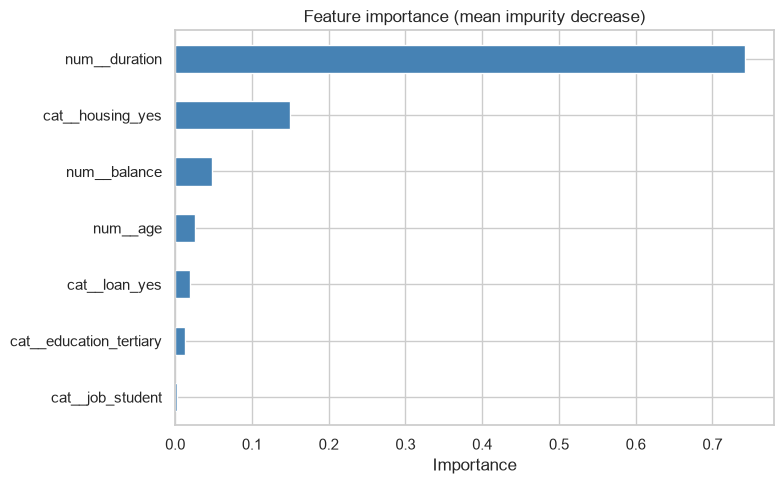

num__duration              0.743
cat__housing_yes           0.149
num__balance               0.048
num__age                   0.025
cat__loan_yes              0.020
cat__education_tertiary    0.012
cat__job_student           0.002


In [20]:
importances = pd.Series(dt_model.feature_importances_, index=transformed_feature_names)
top = importances[importances > 0].sort_values()

plt.figure(figsize=(8, 5))
top.plot.barh(color="steelblue")
plt.title("Feature importance (mean impurity decrease)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print(top.sort_values(ascending=False).round(3).to_string())

> ⚠️ `duration` (length of the last call) dominates. In practice it is only known **after** the call is made,
> so it *leaks* information about the outcome. A realistic model built *before* calling a customer should drop it —
> try this in the exercises!

## 9. Overfitting & the bias–variance trade-off

A tree with unlimited depth can keep splitting until every leaf is pure — it then **memorizes** the training data
(training accuracy ≈ 100 %) but generalizes poorly.

* **Shallow tree** ➜ high **bias** (underfitting): too simple to capture the pattern.
* **Deep tree** ➜ high **variance** (overfitting): fits noise in the training set.

Let's plot train vs. test accuracy as `max_depth` grows.

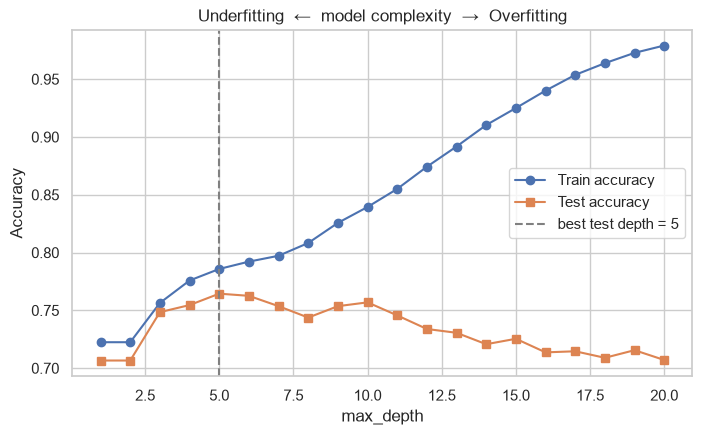

In [21]:
depths = range(1, 21)
train_acc, test_acc = [], []
for d in depths:
    model = Pipeline([('preprocessor', preprocessor),
                      ('classifier', DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

best_d = depths[int(np.argmax(test_acc))]
plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_acc, "o-", label="Train accuracy")
plt.plot(depths, test_acc, "s-", label="Test accuracy")
plt.axvline(best_d, color="grey", ls="--", label=f"best test depth = {best_d}")
plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.title("Underfitting  ←  model complexity  →  Overfitting")
plt.legend(); plt.show()

## 10. Hyper-parameter tuning with cross-validation

Choosing `max_depth` using the **test** set (as above) is cheating — the test set must stay unseen.
Instead we use **k-fold cross-validation** on the training data: split it into $k$ folds, train on $k-1$, validate on the
remaining one, and average:
$$
\text{CV score} = \frac{1}{k}\sum_{i=1}^{k} \text{score}_i
$$
`GridSearchCV` does this for every combination of hyper-parameters.

| Hyper-parameter | Effect |
|---|---|
| `criterion` | `gini` or `entropy` impurity |
| `max_depth` | maximum number of levels |
| `min_samples_split` | minimum samples a node needs before it may split |
| `min_samples_leaf` | minimum samples that must end up in each leaf |

In [22]:
param_grid = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [3, 5, 7, 9, 12],
    'classifier__min_samples_leaf': [1, 10, 30],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print(f"Best CV F1      : {grid.best_score_:.3f}")

y_pred_best = grid.predict(X_test)
print(f"\nTest F1  (tuned)    : {f1_score(y_test, y_pred_best):.3f}   vs  baseline {f1:.3f}")
print(f"Test Acc (tuned)    : {accuracy_score(y_test, y_pred_best):.3f}   vs  baseline {accuracy:.3f}")

Best parameters : {'classifier__criterion': 'gini', 'classifier__max_depth': 9, 'classifier__min_samples_leaf': 30}
Best CV F1      : 0.767

Test F1  (tuned)    : 0.749   vs  baseline 0.757
Test Acc (tuned)    : 0.761   vs  baseline 0.764


> 💬 **Discussion:** the tuned model has the best *cross-validated* F1, yet on this particular test set it is about
> as good as the baseline. CV is an *estimate* averaged over 5 folds; a single test split has its own noise.
> Differences of ±0.01 are usually not meaningful — prefer the simpler model when scores are this close.

## 11. Summary

* A decision tree recursively splits the data, choosing at each node the split $(j^*, t^*)$ that maximizes the
  **impurity decrease** (Gini or entropy).
* Leaves predict the **majority class**; the tree is easy to read and explain.
* Evaluate classifiers with the **confusion matrix**, precision, recall and F1 — not only accuracy.
* Trees **overfit** easily; control complexity with `max_depth`, `min_samples_leaf`, … and choose them with **cross-validation**.

### ✍️ Exercises (fork the repo and try them!)
1. Remove `duration` (data leakage) and re-train. How do the metrics and the root split change?
2. Switch to `criterion='entropy'`. Re-compute the root information gain by hand with the `entropy()` function.
3. Add `month`, `day`, `campaign`, `pdays`, `previous` to the features. Does performance improve?
4. Remove the `StandardScaler` from the pipeline and confirm the predictions are **identical** — why?
5. Use `cost_complexity_pruning_path` and the `ccp_alpha` parameter to **post-prune** the tree.
6. Compare with a `RandomForestClassifier` — what happens to variance?